# Who drops out of online courses, and when?

**Data:** the [Open University Learning Analytics Dataset](https://analyse.kmi.open.ac.uk/open_dataset) (OULAD; Kuzilek, Hlosta & Zdrahal, 2017). It covers 32,593 enrolments of adult distance learners in **7 modules**, across **22 presentations** (runs of a module) in 2013–2014. For each student it records background, assessment results and daily clicks in the online learning platform (the *VLE*).

**Questions**
1. How do courses end for students?
2. Does background matter: deprivation, prior education, workload?
3. **When** do students withdraw?
4. How does online activity differ between students who finish and those who don't?
5. Do disengaged students always withdraw formally?

> Run `python src/build_dataset.py` first.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import style
style.apply()

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=120)

PROC = ROOT / "data" / "processed"
students = pd.read_parquet(PROC / "students.parquet")
vle = pd.read_parquet(PROC / "vle_daily.parquet")
assess = pd.read_parquet(PROC / "assessments.parquet")
schedule = pd.read_parquet(PROC / "assessment_schedule.parquet")
students["not_completed"] = students["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
print(f"{len(students):,} enrolments · {students['id_student'].nunique():,} students · "
      f"{students.groupby(['code_module', 'code_presentation']).ngroups} presentations")

32,593 enrolments · 28,785 students · 22 presentations


## 1. How do courses end?

final_result
Distinction     9.3
Pass           37.9
Fail           21.6
Withdrawn      31.2


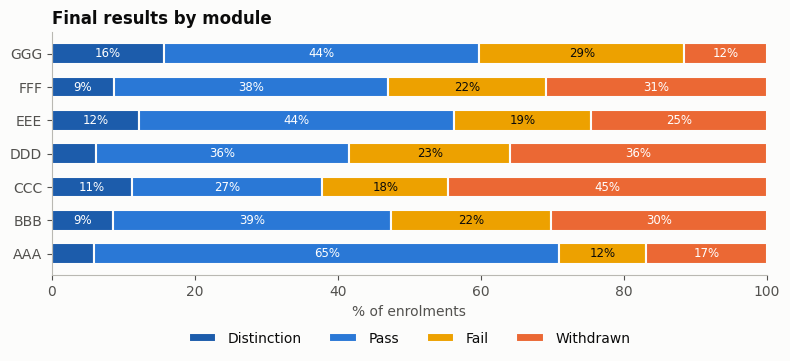

final_result,Distinction,Pass,Fail,Withdrawn
code_module,,,,
AAA,5.9,65.1,12.2,16.8
BBB,8.6,38.9,22.3,30.2
CCC,11.2,26.6,17.6,44.5
DDD,6.1,35.5,22.5,35.9
EEE,12.1,44.1,19.2,24.6
FFF,8.6,38.4,22.0,31.0
GGG,15.6,44.1,28.7,11.5


In [2]:
def stacked_results(df, by, title, name, order=None, figsize=(8, 3.8)):
    """100% stacked horizontal bars of final results per group."""
    tab = pd.crosstab(df[by], df["final_result"], normalize="index")[style.RESULT_ORDER] * 100
    if order is not None:
        tab = tab.loc[order]
    fig, ax = plt.subplots(figsize=figsize)
    left = np.zeros(len(tab))
    for res in style.RESULT_ORDER:
        ax.barh(tab.index.astype(str), tab[res], left=left, color=style.RESULT_COLORS[res], label=res,
                height=0.62, edgecolor=style.SURFACE, linewidth=1.5)
        for i, (l, v) in enumerate(zip(left, tab[res])):
            if v >= 7:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                        color="white" if res != "Fail" else style.TEXT)
        left += tab[res].to_numpy()
    ax.set(xlim=(0, 100), xlabel="% of enrolments", title=title)
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
    ax.grid(False)
    save_fig(name)
    plt.show()
    return tab

overall = students["final_result"].value_counts(normalize=True)[style.RESULT_ORDER]
print((overall * 100).round(1).to_string())
stacked_results(students, "code_module", "Final results by module", "01_results_by_module").round(1)

Across all enrolments, **31% withdraw** and another **22% fail**. Only about half of students finish with a pass or distinction.
The modules differ a lot: in module **CCC**, 45% withdraw; in **GGG**, only 12%. The OU does not publish module names, but its documentation says AAA, BBB and GGG are social-science modules and CCC–FFF are STEM.

From here on we call *withdrawn or failed* **"not completed"**.

## 2. Does background matter?

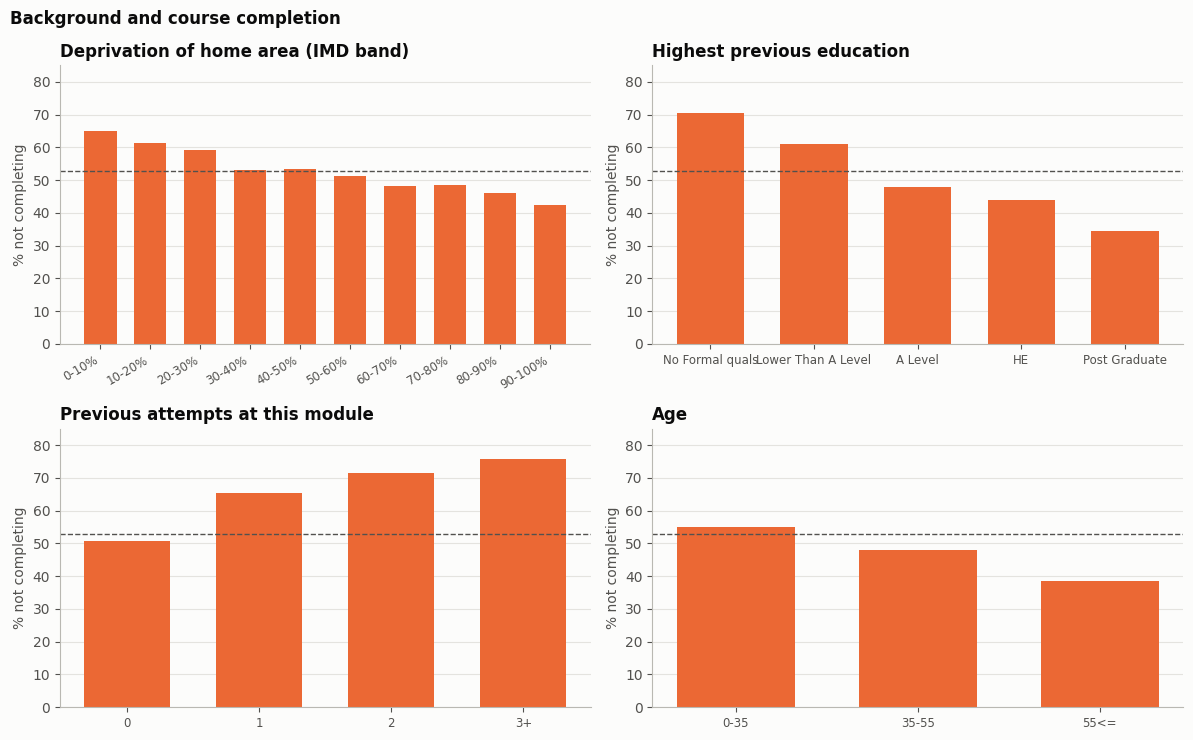

In [3]:
bg = {
    "imd_band": ("Deprivation of home area (IMD band)", ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"]),
    "highest_education": ("Highest previous education", ["No Formal quals", "Lower Than A Level", "A Level or Equivalent", "HE Qualification", "Post Graduate Qualification"]),
    "num_of_prev_attempts": ("Previous attempts at this module", None),
    "age_band": ("Age", ["0-35", "35-55", "55<="]),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (col, (title, order)) in zip(axes.flat, bg.items()):
    d = students.copy()
    if col == "num_of_prev_attempts":
        d[col] = d[col].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
        order = ["0", "1", "2", "3+"]
    rate = d.groupby(col)["not_completed"].mean().reindex(order) * 100
    ax.bar(range(len(rate)), rate, color=style.ORANGE, width=0.65)
    ax.set_xticks(range(len(rate)), [str(i).replace(" or Equivalent", "").replace(" Qualification", "") for i in rate.index],
                  rotation=30 if len(rate) > 5 else 0, ha="right" if len(rate) > 5 else "center", fontsize=8.5)
    ax.axhline(students["not_completed"].mean() * 100, color=style.TEXT_2, lw=1, ls="--")
    ax.set(ylim=(0, 85), ylabel="% not completing", title=title)
    ax.grid(axis="x", visible=False)
fig.suptitle("Background and course completion", x=0.01, ha="left", fontweight="bold")
save_fig("02_background")
plt.show()

In [4]:
for col in ["imd_band", "highest_education", "num_of_prev_attempts", "age_band", "disability", "gender"]:
    print(students.groupby(col)["not_completed"].agg(["mean", "size"]).round(3).T.to_string(), "\n")
workload = students.groupby(pd.cut(students["studied_credits"], [0, 60, 90, 120, 700],
                                   labels=["≤60", "61–90", "91–120", ">120"]), observed=True)["not_completed"].mean()
print("Not completing by credits studied at the same time:", (workload * 100).round(1).to_dict())

imd_band     0-10%    10-20%    20-30%    30-40%    40-50%    50-60%    60-70%    70-80%    80-90%   90-100%         ?
mean         0.648     0.614     0.593     0.531     0.534     0.512     0.481     0.485     0.459     0.425     0.343
size      3311.000  3516.000  3654.000  3539.000  3256.000  3124.000  2905.000  2879.000  2762.000  2536.000  1111.000 

highest_education  A Level or Equivalent  HE Qualification  Lower Than A Level  No Formal quals  Post Graduate Qualification
mean                                0.48             0.438               0.611            0.703                        0.345
size                            14045.00          4730.000           13158.000          347.000                      313.000 

num_of_prev_attempts          0         1        2        3       4       5     6
mean                      0.507     0.654    0.716    0.775   0.667   0.846  0.75
size                  28421.000  3299.000  675.000  142.000  39.000  13.000  4.00 

age_band      0-

Background matters, in the directions you would expect:
- **Deprivation:** 65% of students from the most deprived areas (IMD 0–10%) don't complete, against 43% from the least deprived (90–100%).
- **Prior education:** 70% of students without formal qualifications don't complete, against 44% of those who already hold a degree and 35% of postgraduates.
- **Previous attempts:** students repeating a module are more likely not to complete it again (65% at the second attempt, against 51% at the first).
- **Workload:** students taking more than 120 credits at once (more than a full-time load) don't complete 70% of the time, against 48% for 60 credits or fewer.
- **Disability** (62% vs 52%) and **age** (55% under 35 vs 48% at 35–55) also matter, while gender barely does.

But these differences are gradual. Background shifts the odds; it doesn't determine the outcome. Notebook 02 shows that **background alone predicts poorly**.

## 3. When do students withdraw?

Withdrawals before the course starts (day ≤ 0): 31%
Median withdrawal day: 27 · by day 28: 50% · by day 84: 68%


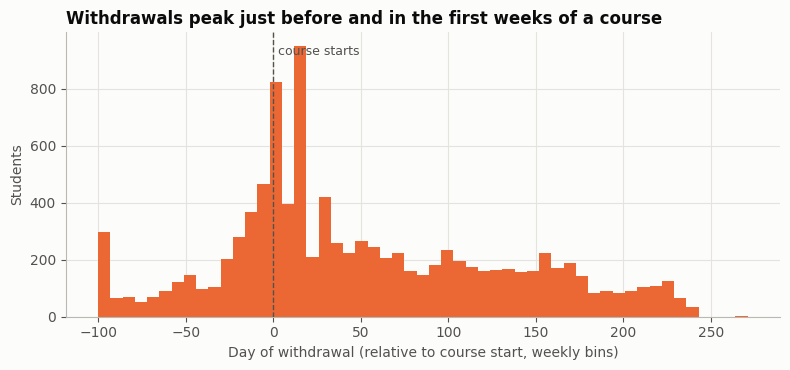

In [5]:
w = students[students["withdrawn"] == 1]
day = w["date_unregistration"].dropna()
print(f"Withdrawals before the course starts (day ≤ 0): {(day <= 0).mean():.0%}")
print(f"Median withdrawal day: {day.median():.0f} · by day 28: {(day <= 28).mean():.0%} · by day 84: {(day <= 84).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(day.clip(-100, 270), bins=np.arange(-100, 275, 7), color=style.ORANGE)
ax.axvline(0, color=style.TEXT_2, lw=1, ls="--")
ax.text(3, ax.get_ylim()[1] * 0.92, "course starts", fontsize=9, color=style.TEXT_2)
ax.set(xlabel="Day of withdrawal (relative to course start, weekly bins)", ylabel="Students",
       title="Withdrawals peak just before and in the first weeks of a course")
save_fig("03_withdrawal_timing")
plt.show()

About **30% of withdrawals happen before the course even starts**. Half of all withdrawals have happened by day 27, and two-thirds by day 84 (week 12).
For an early-warning system that is good and bad news. There is a window to act, but it is **short**: by the time a tutor has seen a student's first assignment, many at-risk students have already gone.

## 4. Online activity: finishers vs non-finishers

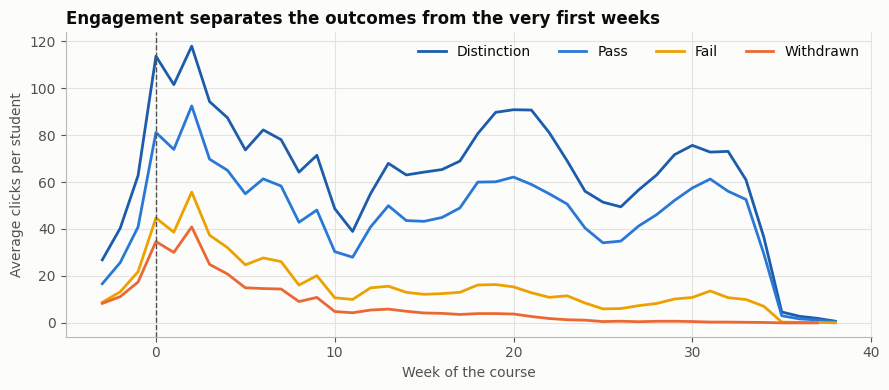

In [6]:
weekly = vle.assign(week=vle["date"] // 7).groupby(["code_module", "code_presentation", "id_student", "week"])["clicks"].sum().reset_index()
weekly = weekly.merge(students[["code_module", "code_presentation", "id_student", "final_result"]],
                      on=["code_module", "code_presentation", "id_student"])
# average weekly clicks per enrolled student (students with no clicks that week count as 0)
n_by_result = students["final_result"].value_counts()
curve = weekly.groupby(["final_result", "week"])["clicks"].sum().unstack(0) / n_by_result
curve = curve.loc[-3:38, style.RESULT_ORDER]

fig, ax = plt.subplots(figsize=(9, 4))
for res in style.RESULT_ORDER:
    ax.plot(curve.index, curve[res], color=style.RESULT_COLORS[res], label=res, lw=2)
ax.axvline(0, color=style.TEXT_2, lw=1, ls="--")
ax.set(xlabel="Week of the course", ylabel="Average clicks per student", title="Engagement separates the outcomes from the very first weeks")
ax.legend(ncol=4, loc="upper right")
save_fig("04_weekly_clicks")
plt.show()

The four outcomes separate **early**. Students who will withdraw or fail click less from the first weeks, and even **before the course starts**, when early-registered students can already browse materials.
Activity of future withdrawals falls towards zero as they leave. Students who will **fail** keep a low level of activity for longer.

### The first assignment

First assignment is due on day 22 (median across presentations)


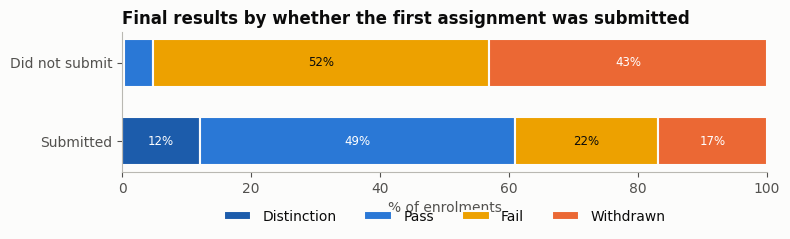

final_result,Distinction,Pass,Fail,Withdrawn
first,,,,
Submitted,12.0,48.9,22.3,16.8
Did not submit,0.2,4.5,52.2,43.1


In [7]:
first = (schedule[schedule["assessment_type"] != "Exam"].sort_values("date")
         .groupby(["code_module", "code_presentation"]).head(1)[["code_module", "code_presentation", "id_assessment", "date"]])
did = assess.merge(first[["id_assessment"]], on="id_assessment")[["code_module", "code_presentation", "id_student"]].assign(submitted_first=1)
s1 = students.merge(first[["code_module", "code_presentation"]], on=["code_module", "code_presentation"]) \
             .merge(did, on=["code_module", "code_presentation", "id_student"], how="left").fillna({"submitted_first": 0})
# only students still enrolled when the first assignment was due
due = s1.merge(first, on=["code_module", "code_presentation"])
due = due[due["date_unregistration"].isna() | (due["date_unregistration"] > due["date"])]
print(f"First assignment is due on day {first['date'].median():.0f} (median across presentations)")
stacked_results(due.assign(first=due["submitted_first"].map({1: "Submitted", 0: "Did not submit"})), "first",
                "Final results by whether the first assignment was submitted", "05_first_assignment",
                order=["Submitted", "Did not submit"], figsize=(8, 2.6)).round(1)

Not submitting the **first assignment** (due around day 22) is one of the strongest single warning signs: **fewer than 1 in 20** of these students go on to pass, against 61% of those who submit.

## 5. Silent disengagement

In [8]:
sys.path.append(str(ROOT / "src"))
from features import snapshot
s56 = snapshot(56)
s56 = s56[s56["date_registration"].isna() | (s56["date_registration"] <= 56)]
inactive = s56["clicks_last_7_days"] == 0
tab = pd.crosstab(np.where(inactive, "No clicks in week 8", "Active in week 8"), s56["final_result"], normalize="index")[style.RESULT_ORDER]
print(f"Students still enrolled at week 8 with no clicks that week: {inactive.mean():.0%}")
(tab * 100).round(1)

Students still enrolled at week 8 with no clicks that week: 26%


final_result,Distinction,Pass,Fail,Withdrawn
row_0,,,,
Active in week 8,13.6,53.7,19.3,13.4
No clicks in week 8,5.3,26.5,46.9,21.2


Among students still enrolled in week 8 who **did not log in at all that week**, about 47% end up **failing** and about 21% **withdraw formally**. More than twice as many simply drift away and fail as officially leave.

This changes how to define the problem. A model trained only to predict formal **withdrawal** treats a silently disengaged student who ends up failing as a "success". For an early-warning system, the useful target is **not completing**, whether by withdrawing or by failing. Notebook 02 compares both.

## Summary
- Only about half of enrolments end in a pass or distinction: **31% withdraw** and **22% fail**.
- Deprivation, prior education, previous attempts and workload all matter, but gradually.
- About **30% of withdrawals happen before day 0**, and half by day 27. The window to act is short.
- Engagement separates outcomes from the first weeks, and the **first assignment** is a strong signal.
- **Disengagement is often silent**: inactive students more often fail than formally withdraw.